# Part 2 — Data Augmentation
Balance the dataset by augmenting minority classes with 6 techniques:
Flip · Rotate · Skew · Shear · Crop · Distortion

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import argparse

import matplotlib.pyplot as plt

from src.augmentation import (
    TRANSFORMS,
    augment_one,
    balance_dataset,
    load_rgb,
    save_augmentations,
)
from src.data import CLASSES, DATA_PATH, resolve_images

HELP_TEXT = """Usage:
  Augmentation.py <image_path>       Display and save 6 augmentations for one image
  Augmentation.py -h                 Show this help message

When run without arguments, balances the full dataset into augmented_directory/."""


def parse_args():
    parser = argparse.ArgumentParser(description="Data Augmentation", add_help=False)
    parser.add_argument("-h", "--help", action="store_true", help="Show help message")
    parser.add_argument("image", nargs="?", default=None, help="Path to a single image")
    return parser.parse_args()

In [2]:
data = resolve_images(DATA_PATH, CLASSES)
counts = {k: len(v) for k, v in data.items()}
max_len = max(counts.values())
print("Class counts:")
for c, n in counts.items():
    print(f"  {c:20s}  {n}  {'*' * (n // 30)}")
print(f"\nMajority = {max_len}, total = {sum(counts.values())}")

Class counts:
  Apple_Black_rot       620  ********************
  Apple_healthy         1646  ******************************************************
  Apple_rust            275  *********
  Apple_scab            629  ********************
  Grape_Black_rot       1178  ***************************************
  Grape_Esca            1382  **********************************************
  Grape_healthy         422  **************
  Grape_spot            1075  ***********************************

Majority = 1646, total = 7227


## Display 6 augmentations on one image

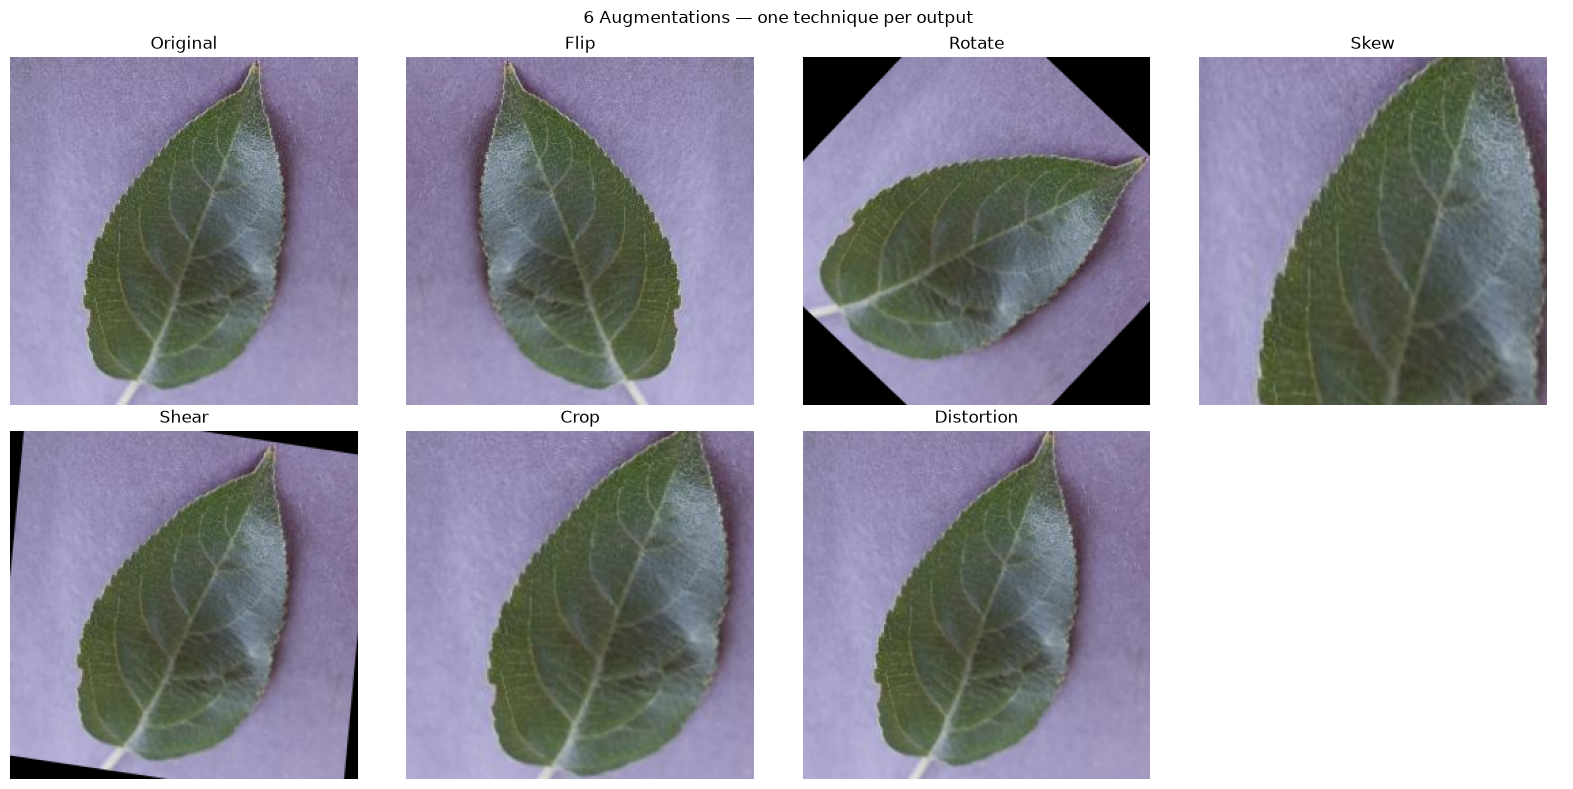

In [3]:
sample_path = data["Apple_healthy"][0]
sample = load_rgb(sample_path)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes[0, 0].imshow(sample)
axes[0, 0].set_title("Original")
axes[0, 0].axis("off")
for ax, (name, tfm) in zip(axes.flat[1:], TRANSFORMS.items()):
    ax.imshow(augment_one(sample, tfm))
    ax.set_title(name)
    ax.axis("off")
axes.flat[-1].axis("off")
plt.suptitle("6 Augmentations — one technique per output")
plt.tight_layout()
plt.show()

## Save with subject naming convention

In [4]:
for f in save_augmentations(sample_path):
    print(f)

/home/samy/Leaffliction/data/leaves/images/Apple_healthy/image (456)_Flip.JPG
/home/samy/Leaffliction/data/leaves/images/Apple_healthy/image (456)_Rotate.JPG
/home/samy/Leaffliction/data/leaves/images/Apple_healthy/image (456)_Skew.JPG
/home/samy/Leaffliction/data/leaves/images/Apple_healthy/image (456)_Shear.JPG
/home/samy/Leaffliction/data/leaves/images/Apple_healthy/image (456)_Crop.JPG
/home/samy/Leaffliction/data/leaves/images/Apple_healthy/image (456)_Distortion.JPG


## Balance dataset into augmented_directory/

In [5]:
out = balance_dataset(
    data, max_len=max_len, out_dir=str(Path.cwd().parent / "augmented_directory")
)
print(f"Saved to {out}")

Saved to /home/samy/Leaffliction/augmented_directory


## Verify balanced distribution

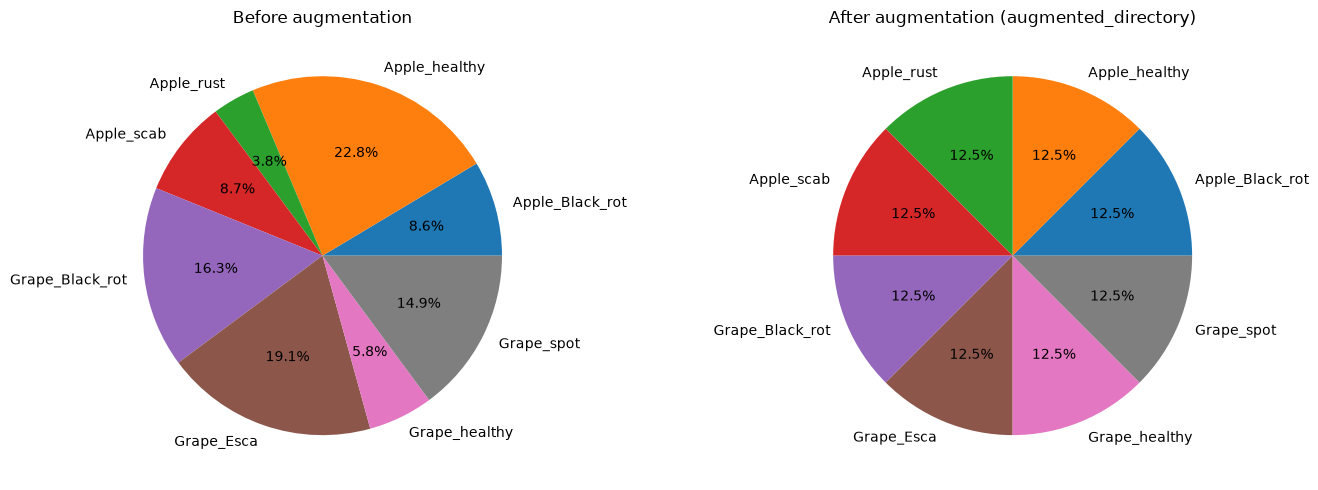

In [6]:
balanced = resolve_images(Path.cwd().parent / "augmented_directory", CLASSES)
b_counts = {k: len(v) for k, v in balanced.items()}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].pie(list(counts.values()), labels=list(counts.keys()), autopct="%1.1f%%")
axes[0].set_title("Before augmentation")
axes[1].pie(list(b_counts.values()), labels=list(b_counts.keys()), autopct="%1.1f%%")
axes[1].set_title("After augmentation (augmented_directory)")
plt.tight_layout()
plt.show()

## CLI mode (when converted to script)
Run `./Augmentation.py <image_path>` to augment a single image.

In [7]:
if __name__ == "__main__" or "ipykernel" in sys.modules:
    try:
        args = parse_args()
    except SystemExit:
        args = argparse.Namespace(help=False, image=None)

    if getattr(args, "help", False):
        print(HELP_TEXT)
    elif getattr(args, "image", None):
        img_path = Path(args.image)
        assert img_path.exists(), f"Image not found: {img_path}"
        print(f"Augmenting: {img_path}")
        saved = save_augmentations(img_path)
        for f in saved:
            print(f"  {f}")

usage: ipykernel_launcher.py [-h] [image]
ipykernel_launcher.py: error: unrecognized arguments: --f=/run/user/1000/jupyter/runtime/kernel-v314b2f81ced715cf0a3cae14540bf1a933851e9e9.json
